In [9]:
# Environment Check
import sys
print(sys.version)
# Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import StandardScaler as SS
from sklearn.linear_model import LogisticRegression as LR
from sklearn.metrics import confusion_matrix as cm
from scipy.stats import pearsonr
import statsmodels.formula.api as smf

import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
load_dotenv()


3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]


True

# (P)redicting Results

This notebook is a continuation of the A(r)senal Analysis project. It focuses on analyzing player performance metrics for Arsenal Football Club for the 2024-2025 season of the English Premier League and will use Python for data analysis and visualization. Unlike the previous notebook, we will be annotating each section (including the code) to show learning path and thought process.

## Introduction


## Research Question
For this analysis, the initial question driving our exploration was, "Given that our previous analysis showed that xG explained team performance over time, how much of a predictive signal does it contain at the match level?". That said, our initial attempt showed us just how complex football matches are, and that xG, xGA, and their related metrics only tell part of the story. Therefore, we refined our research question to: **"At which point does xG fail?"**. 

## Section I: Validation
To align ourselves properly with the first phase of the analysis, we will reproduce the original findings in Python, particularly the relationship between xG and the actual goals scored. This will involve using the same data sources and similar methodologies to ensure that our results are comparable. Answering the research question will follow upon the successful reproduction of the original analysis.

### Data Preparation and Model Initialization
Similar to the previous notebook, we will use an .env file to store all private database credentials. This is a best practice to ensure sensitive information is not hard-coded into the script. A verification step is included to ensure that the environment variables are loaded correctly.

#### Data Extraction and Preparation
First, we pull the relevant data from the database. To validate, we will be using the league summary tables that include xG and xGA metrics for each team. The data will be used to recreate the findings from the original analysis.

In [10]:
# Loading environment variables
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_NAME = os.getenv("DB_NAME")
DB_PORT = os.getenv("DB_PORT")

engine = create_engine(f"mysql+mysqlconnector://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}", connect_args={"use_pure": True})

pl_table_24 = pd.read_sql("SELECT * FROM pl_table_24", engine)
pl_table_23 = pd.read_sql("SELECT * FROM pl_table_23_24", engine)

# Validating Data Load
print(pl_table_24.shape)
print(pl_table_23.shape)
print(pl_table_23.columns)

(20, 16)
(20, 20)
Index(['id', 'rk', 'team_name', 'mp', 'w', 'd', 'l', 'gf', 'ga', 'gd', 'pts',
       'pts_mp', 'xg', 'xga', 'xgd', 'xgd_90', 'attendance', 'top_scorer',
       'top_scorer_goals', 'goalkeeper'],
      dtype='object')


With our data extracted, we'll wrangle the two tables into a single DataFrame that contains all necessary metrics for analysis. This includes labeling each season accordingly then concatenating the two DataFrames. We will be using the concatenated DataFrame later on. 

In [11]:
pl_table_23["season"] = "2023-24"
pl_table_24["season"] = "2024-25"


pl_table_combined = pd.concat([pl_table_23, pl_table_24], ignore_index=True)

xg_all = pl_table_combined[["team_name", "gf", "ga", "xg", "xga", "season"]]

# Checking the combined data
print(xg_all)
xg_all.groupby("season").size()

            team_name  gf   ga    xg   xga   season
0     Manchester City  96   34  80.5  35.6  2023-24
1             Arsenal  91   29  76.1  27.9  2023-24
2           Liverpool  86   41  87.8  45.7  2023-24
3         Aston Villa  76   61  63.3  59.9  2023-24
4           Tottenham  74   61  68.2  63.4  2023-24
5             Chelsea  77   63  74.5  58.1  2023-24
6    Newcastle United  85   62  76.0  61.4  2023-24
7   Manchester United  57   58  56.5  68.9  2023-24
8     West Ham United  60   74  52.3  71.1  2023-24
9      Crystal Palace  57   58  48.6  52.0  2023-24
10           Brighton  55   62  56.8  55.4  2023-24
11        Bournemouth  54   67  55.9  58.1  2023-24
12             Fulham  55   61  50.8  62.9  2023-24
13             Wolves  50   65  46.7  67.7  2023-24
14            Everton  40   51  54.0  55.2  2023-24
15          Brentford  56   65  58.2  56.0  2023-24
16  Nottingham Forest  49   67  49.9  53.3  2023-24
17         Luton Town  52   85  42.4  78.0  2023-24
18          

season
2023-24    20
2024-25    20
dtype: int64

Now that the data is prepared, we can proceed to using Pearson correlation on "pl_table_23" to validate the relationship between xG and actual goals scored for the 2023-2024 season.

In [15]:
r_xg_gf_23, p_xg_gf_23 = pearsonr(pl_table_23["xg"], pl_table_23["gf"])
r_xga_ga_23, p_xga_ga_23 = pearsonr(pl_table_23["xga"], pl_table_23["ga"])

print(f"xG vs GF 2023-24: r = {r_xg_gf_23: .2f}, p = {p_xg_gf_23: .3e}")
print(f"xGA vs GA 2023-24: r = {r_xga_ga_23: .2f}, p = {p_xga_ga_23: .3e}")

# Modelling with interaction term
model = smf.ols(
    formula="gf ~ xg * season",
    data=xg_all
).fit()

print(model.summary())


xG vs GF 2023-24: r =  0.92, p =  6.413e-09
xGA vs GA 2023-24: r =  0.88, p =  3.173e-07
                            OLS Regression Results                            
Dep. Variable:                     gf   R-squared:                       0.846
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     65.83
Date:                Tue, 16 Dec 2025   Prob (F-statistic):           1.09e-14
Time:                        15:39:04   Log-Likelihood:                -130.81
No. Observations:                  40   AIC:                             269.6
Df Residuals:                      36   BIC:                             276.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

Our analysis in Python confirms the strong positive correlation between xG and actual goals scored (GF) as well as between xGA and actual goals conceded (GA). With an $r$ value of approximately **.92 for goals scored** and **.88 for goals conceded**, we can confirm that the original findings regarding the relationship between xG and GF (for the season 2023-2024) hold true. This indicates that xG explains a significant portion of the variance in goals scored and conceded. Extending this analysis to include data from multiple seasons, we observe that the strong correlation persists, with an $R^2$ of **.85** when considering the relationship between xG and GF across different seasons.

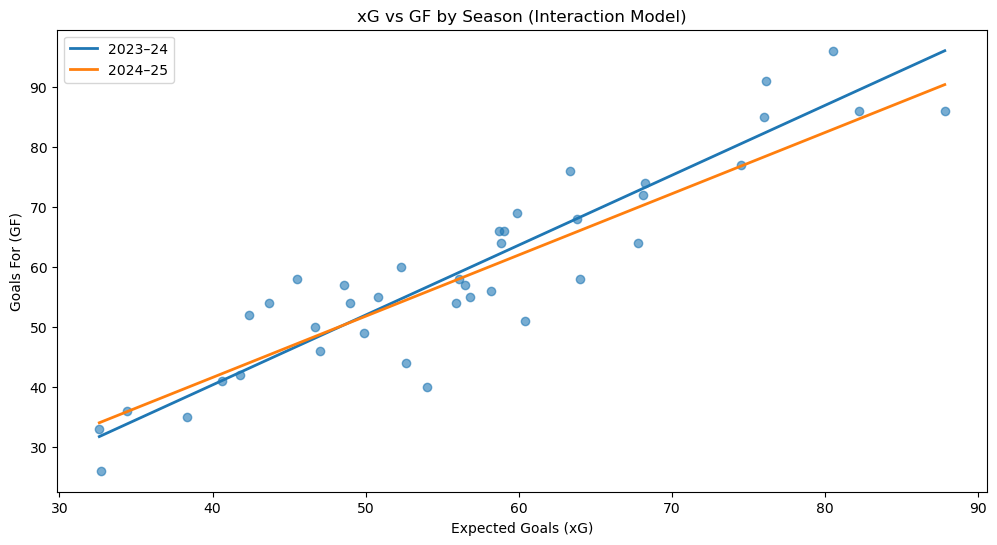

In [19]:
# Plotting the results

plt.figure(figsize=(12, 6))
plt.scatter(xg_all["xg"], xg_all["gf"], alpha=0.6)

# Create a smooth xG range
xg_range = np.linspace(xg_all["xg"].min(), xg_all["xg"].max(), 100)

# 2023–24 prediction
df_2324 = pd.DataFrame({
    "xg": xg_range,
    "season": "2023-24"
})

plt.plot(
    xg_range,
    model.predict(df_2324),
    linewidth=2,
    label="2023–24"
)

# 2024–25 prediction
df_2425 = pd.DataFrame({
    "xg": xg_range,
    "season": "2024-25"
})

plt.plot(
    xg_range,
    model.predict(df_2425),
    linewidth=2,
    label="2024–25"
)

plt.xlabel("Expected Goals (xG)")
plt.ylabel("Goals For (GF)")
plt.title("xG vs GF by Season (Interaction Model)")
plt.legend()
plt.show()

As before, we can see a strong relationship between xG and actual goals scored. With both regression lines showing a positive trend we can be confident in the findings of the original analysis. Likewise, the graph *also* shows that that xG fails to account for all the variance in actual goals scored, as evidenced by the spread of data points around the regression line. This suggests that while xG is a strong predictor of goals scored, other factors also play a significant role in determining actual outcomes in football matches.

This will drive our further analysis into understanding the limitations of xG as a predictive metric at the match level.

### Data Extraction and Preparation
The first step we will take is extracting the general match data from the database. This should allow us to get a better understanding of the context in which players performed. We'll try to pull what we can from the data, just in case we find something worth analyzing.

In [13]:
# Extracting Match Data from Database

sql_query = """
SELECT
    m.match_date,
    ht.team_name AS Home_Team,
    at.team_name AS Away_Team,
    m.home_score AS Home_GF,
    m.away_score AS Away_GF,
    m.home_xg AS Home_xG,
    m.away_xg AS Away_xG
FROM pl_matches m
JOIN pl_teams ht ON m.home_team_id = ht.team_id
JOIN pl_teams at ON m.away_team_id = at.team_id
ORDER BY m.match_date;
"""

# Extracting into Pandas Dataframe

cursor = db_conn.cursor(dictionary=True) # dictionary=True returns results as dictionaries, ideal for Pandas
cursor.execute(sql_query)
# The pd.DataFrame() function handles the transfer of SQL results to a Pandas DataFrame
match_data_raw = pd.DataFrame(cursor.fetchall())
cursor.close()

# Converting match_date to datetime format
match_data_raw['match_date'] = pd.to_datetime(match_data_raw['match_date'])


# Converting Home_xG and Away_xG to numeric, coercing errors to NaN
match_data_raw['Home_xG'] = pd.to_numeric(match_data_raw['Home_xG'], errors='coerce')
match_data_raw['Away_xG'] = pd.to_numeric(match_data_raw['Away_xG'], errors='coerce')


# Validating Data Extraction
print("--- Raw Match Data Structure ---")
print(match_data_raw.info())
print("\n--- Raw Match Data Head ---")
print(match_data_raw.head())

NameError: name 'db_conn' is not defined

Given the format the data was in, we'll need to wrangle it into a more usable format. We'll rename columns for clarity, convert data types as necessary, and handle any missing values.

In [ ]:
# Converting match_data_raw to long format for easier analysis

home_df = match_data_raw.rename(columns={
    'Home_Team': 'Team',      # The Home Team is now "Team"
    'Away_Team': 'Opponent',  # The Away Team is now "Opponent"
    'Home_GF': 'GF',          # Home Goals now "Goals For"
    'Away_GF': 'GA',          # Away Goals now "Goals Against"
    'Home_xG': 'xG',
    'Away_xG': 'xGA'
})

# Add a label 
home_df['Location'] = 'Home'

away_df = match_data_raw.rename(columns={
    'Away_Team': 'Team',  # The Away Team is now "Team"
    'Home_Team': 'Opponent',      # The Home Team is now "Opponent"
    'Home_GF': 'GF',          # Home Goals now "Goals For"
    'Away_GF': 'GA',          # Away Goals now "Goals Against"
    'Home_xG': 'xG',
    'Away_xG': 'xGA'
})

away_df['Location'] = 'Away'

# Concatenating home and away dataframes
team_match_data = pd.concat([home_df, away_df], ignore_index=True)

# Sorting by match_date for chronological order
team_match_data = team_match_data.sort_values(by=['Team', 'match_date']).reset_index(drop=True)



## Confirming Our Assumptions with Logistic Regression and Rolling Averages
Given that in the previous phase of the project we found that xG was a reliable predictor for team performance, we'll first try to use logistic regression to see if we can predict match outcomes based on xG, xGA, and other relevant metrics. This will help us understand the impact of these metrics on match results. We'll also make use of rolling averages to smooth out short-term fluctuations and highlight longer-term trends in team performance. 

In [ ]:
# Preparing data for modeling

## Defining variables
window_size = 5

## Rolling averages for performance metrics
team_match_data['Rolling_xG_For'] = team_match_data.groupby('Team')['xG'].rolling(window=window_size).mean().reset_index(0, drop=True).shift(1)

team_match_data['Rolling_xG_Against'] = team_match_data.groupby('Team')['xGA'].rolling(window=window_size).mean().reset_index(0, drop=True).shift(1)

## Defining variable for opponent rolling averages
opponent_features = team_match_data[['match_date', 'Team', 'Rolling_xG_For', 'Rolling_xG_Against']]

### Merging rolling averages back into main dataframe
team_match_data = team_match_data.merge(
    opponent_features,
    left_on=['match_date', 'Opponent'],
    right_on=['match_date', 'Team'],
    suffixes=('_Team', '_Opponent'),
    how='left'
)

## Renaming columns for clarity
team_match_data.rename(columns={
    'Rolling_xG_For_Opponent': 'Opponent_Rolling_xG_For',
    'Rolling_xG_Against_Opponent': 'Opponent_Rolling_xG_Against'
}, inplace=True)

## Dropping redundant 'Team' column from opponent merge
team_match_data.drop(columns=['Team_Opponent'], inplace=True)

## Fixing 'Team' column name
team_match_data.rename(columns={'Team_Team': 'Team'}, inplace=True)

## Establish Target Variable
team_match_data['Target'] = (team_match_data['GF'] > team_match_data['GA']).astype(int)

## Encoding Location as Binary Variable
team_match_data['At_Home']= team_match_data['Location'].map({'Home': 1, 'Away': 0})

## Drop rows where rolling features are NA (the first 4 games for each team)
team_match_data.dropna(inplace=True)

## Verify how many rows are left
print(f"\nTotal rows ready for modeling: {len(team_match_data)}")

## Verifying the prepared data
arsenal_data = team_match_data[team_match_data['Team'] == 'Arsenal'].head(10)



In [ ]:
## Distribution Check
print("Target Distribution (Win vs. Not Win):")
print(team_match_data['Target'].value_counts(normalize=True))

## Arsenal Data Sample for verification
print("\n--- Arsenal Data Sample ---")
print(arsenal_data.head(10))

arsenal_data.describe()

Training the model will follow recommended practice of splitting the data into training and testing sets to evaluate model performance effectively. For this purpose, we'll use an 80-20 split.

In [ ]:
# Model Training and Evaluation Chunks
## Selecting features and target variable
features = [
    'Rolling_xG_For_Team',
    'Rolling_xG_Against_Team',
    'Opponent_Rolling_xG_For',
    'Opponent_Rolling_xG_Against',
    'At_Home'
]

X = team_match_data[features]
y = team_match_data['Target']

## Splitting data into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = tts(X, y, test_size=0.2, random_state=42)

# Validating the split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

In [ ]:
# Scaling Features, Model Training, and Evaluation

## Initializing StandardScaler
scaler = SS()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Validating scaling
print("X_train_scaled (first 5 rows):\n", X_train_scaled[:5])
print("X_test_scaled (first 5 rows):\n", X_test_scaled[:5])

## Training the Model
model = LR(random_state=42)

model.fit(X_train_scaled, y_train)

## Prediction and Evaluation
y_pred = model.predict(X_test_scaled)

## Calculate confusion matrix
conf_matrix = cm(y_test, y_pred)

## Assigning test_accuracy variable
test_accuracy = model.score(X_test_scaled, y_test)


In [ ]:
# Display confusion matrix and model accuracy
print("\nConfusion Matrix:")
print(conf_matrix)

## Display model accuracy on test set
print(f"\nModel Accuracy on Test Set: {model.score(X_test_scaled, y_test):.4f}")



## Reassessing Our Approach

Based on the results of the initial training and validation, we have found that our model's accuracy is not meeting our expectations, returning an **accuracy score of 59.56%**. The confusion matrix reveals that the model correctly identified **almost none** of the positive class, indicative of poor recall and severe class imbalance.

 To improve our model, we will:
1. **Feature Engineering**: We will reassess and improve the features used in the model. 
2. **Model Evaluation**: ROC-AUC to handle class imbalance, and improving precision and recall.
3. **Hyperparameter Tuning**: Adjust model tuning to optimize performance.
4. **Cross-Validation**: Implement k-fold cross-validation to ensure robustness.
5. **Player-level Analysis**: Conduct a detailed analysis of individual player performance metrics instead of team metrics. 

In [ ]:
print(team_match_data.head())

In [ ]:
# Closing the database connection
cursor.close()
db_conn.close()